<a href="https://colab.research.google.com/github/nahdaauliya/PCVK_Ganjil_2026/blob/main/week10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt
import os

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


###2. Template Matching

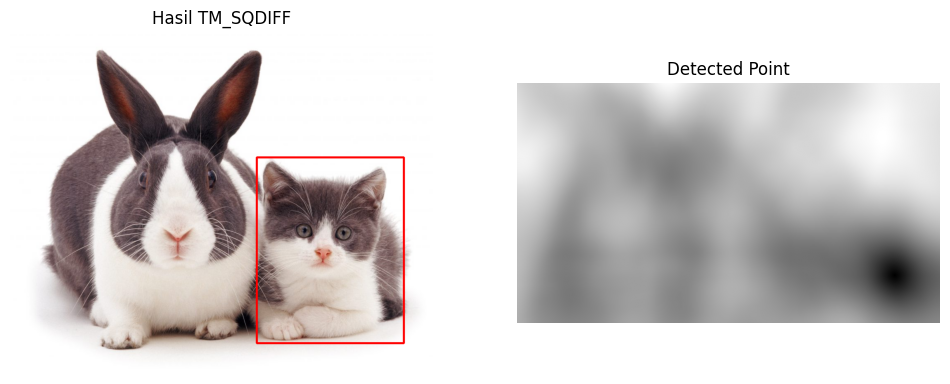

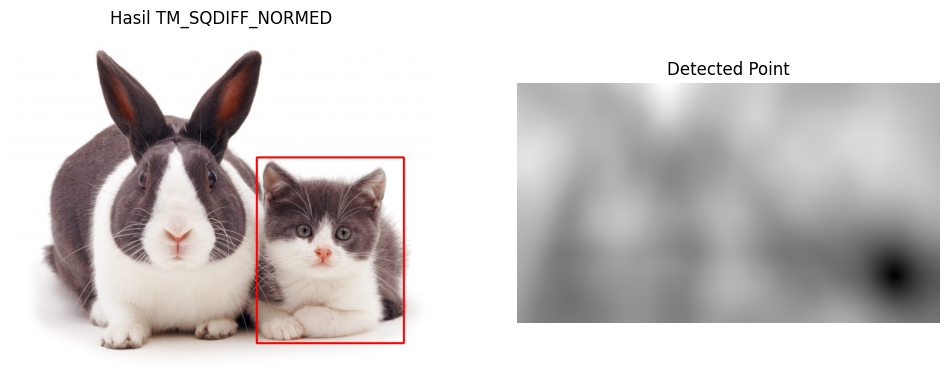

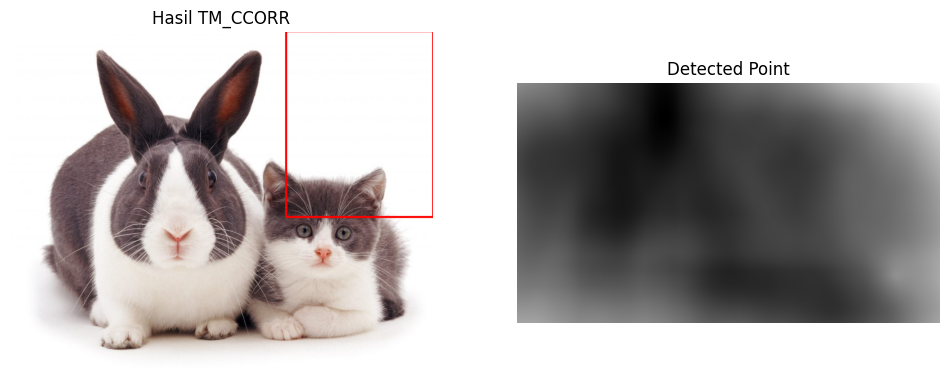

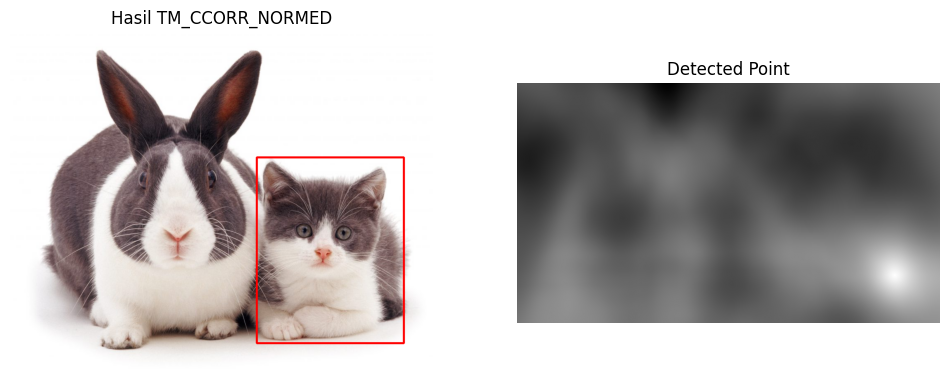

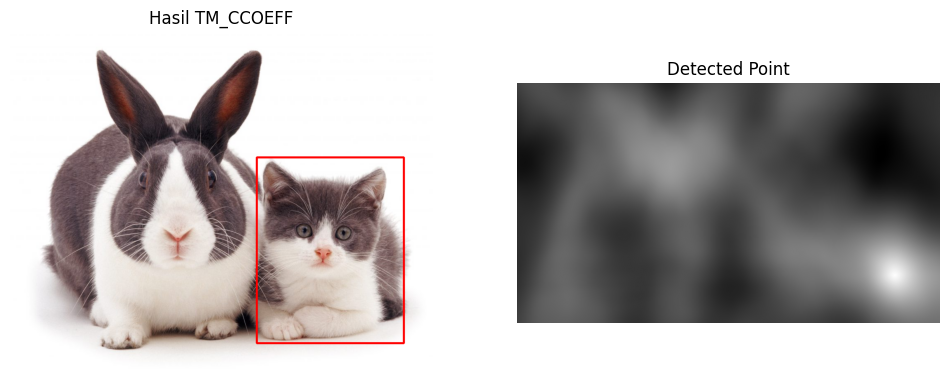

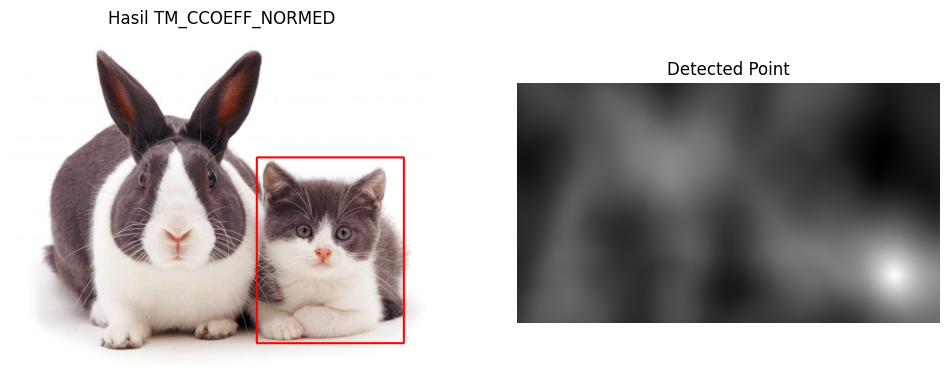

In [ ]:
folder = '/content/drive/MyDrive/PCVK/Images (2)/Images/Object Detection'

img_path = os.path.join(folder, 'cats_and_bunnies.jpg')
template_path = os.path.join(folder, 'cat2_templatejpg.jpg')

img = cv.imread(img_path)
template = cv.imread(template_path)

if img is None or template is None:
  raise FileNotFoundError(
      "Gambar tidak ditemukan. Periksa folder dan nama file."
  )

img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
template_gray = cv.cvtColor(template, cv.COLOR_BGR2GRAY)
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

h, w = template_gray.shape

methods = [
    ('TM_SQDIFF', cv.TM_SQDIFF),
    ('TM_SQDIFF_NORMED', cv.TM_SQDIFF_NORMED),
    ('TM_CCORR', cv.TM_CCORR),
    ('TM_CCORR_NORMED', cv.TM_CCORR_NORMED),
    ('TM_CCOEFF', cv.TM_CCOEFF),
    ('TM_CCOEFF_NORMED', cv.TM_CCOEFF_NORMED),
]

for nama, method in methods:
  result = cv.matchTemplate(
      img_gray, template_gray, method
  )

  min_val, max_val, min_loc, max_loc  = cv.minMaxLoc(result)

  if method in[cv.TM_SQDIFF, cv.TM_SQDIFF_NORMED]:
    lokasi = min_loc
  else:
    lokasi = max_loc

  x, y = lokasi
  hasil = img_rgb.copy()

  cv.rectangle(
      hasil, (x, y), (x + w, y + h),
      (255, 0, 0), 3
  )

  plt.figure(figsize=(12, 5))

  plt.subplot(1, 2, 1)
  plt.imshow(hasil)
  plt.title(f'Hasil {nama}')
  plt.axis('off')

  plt.subplot(1, 2, 2)
  plt.imshow(result, cmap='gray')
  plt.title('Detected Point')
  plt.axis('off')

  plt.show()

###3. Template Matching without OpenCV

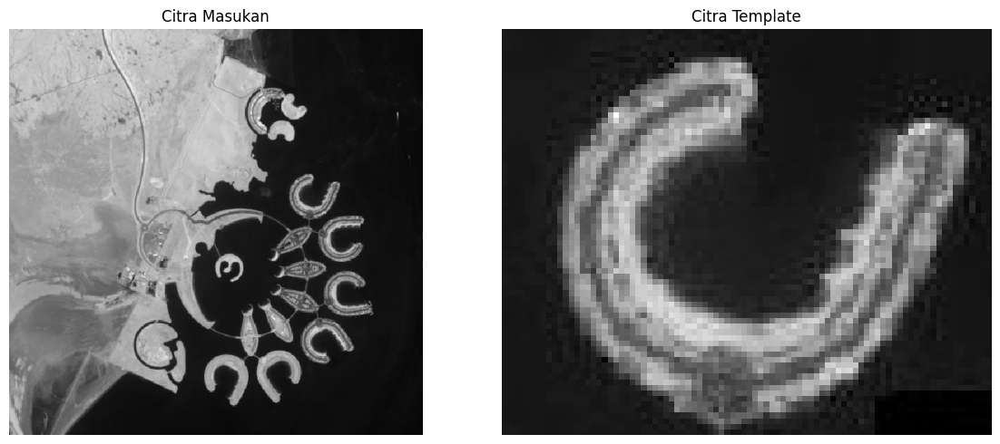

Pencarian selesai.
Jumlah kandidat: 29240
Objek 1: koordinat=(393, 204), kemiripan=0.9642


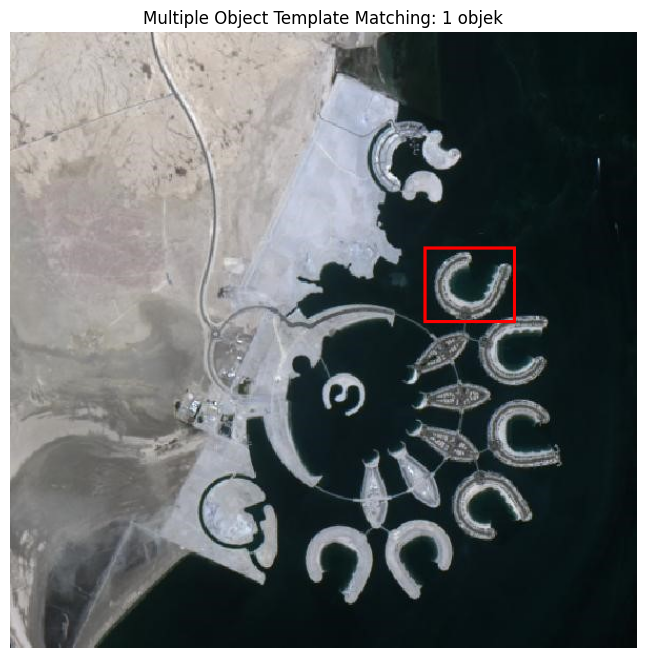

In [ ]:
import os
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# 1. Membaca gambar
folder = '/content/drive/MyDrive/PCVK/Images (2)/Images/Object Detection'
img_path = os.path.join(folder, 'bahrain.jpg')
template_path = os.path.join(folder, 'bahrain-template.jpg')

img = cv.imread(img_path)
template = cv.imread(template_path)

if img is None or template is None:
    raise FileNotFoundError(
        "Gambar tidak ditemukan. Periksa nama file dan lokasi folder."
    )

img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
template_gray = cv.cvtColor(template, cv.COLOR_BGR2GRAY)

# 2. Menampilkan gambar input dan template
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_gray, cmap='gray')
plt.title('Citra Masukan')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(template_gray, cmap='gray')
plt.title('Citra Template')
plt.axis('off')

plt.tight_layout()
plt.show()

# 3. Persiapan template matching manual menggunakan NumPy
source = img_gray.astype(np.float32)
temp = template_gray.astype(np.float32)

H, W = source.shape
h, w = temp.shape

if h > H or w > W:
    raise ValueError("Ukuran template lebih besar daripada citra masukan.")

temp_centered = temp - np.mean(temp)
temp_norm = np.sqrt(np.sum(temp_centered ** 2))

if temp_norm == 0:
    raise ValueError("Template memiliki intensitas seragam.")

# 4. Mencari objek secara manual
candidates = []
step = 3  # Gunakan 1 untuk pencarian lebih teliti, tetapi lebih lambat

for y in range(0, H - h + 1, step):
    for x in range(0, W - w + 1, step):
        patch = source[y:y + h, x:x + w]

        patch_centered = patch - np.mean(patch)
        patch_norm = np.sqrt(np.sum(patch_centered ** 2))

        if patch_norm == 0:
            continue

        score = np.sum(patch_centered * temp_centered) / (
            patch_norm * temp_norm
        )

        candidates.append((score, x, y))

print("Pencarian selesai.")
print("Jumlah kandidat:", len(candidates))

# 5. Memilih hasil deteksi berdasarkan tingkat kemiripan
candidates.sort(key=lambda item: item[0], reverse=True)

threshold = 0.75
selected = []

for score, x, y in candidates:
    if score < threshold:
        break

    overlap = False

    for _, sx, sy in selected:
        intersection_w = max(
            0, min(x + w, sx + w) - max(x, sx)
        )
        intersection_h = max(
            0, min(y + h, sy + h) - max(y, sy)
        )

        intersection = intersection_w * intersection_h
        union = 2 * w * h - intersection
        iou = intersection / union if union > 0 else 0

        if iou > 0.3:
            overlap = True
            break

    if not overlap:
        selected.append((score, x, y))

# 6. Menggambar kotak pada objek yang terdeteksi
result = cv.cvtColor(img, cv.COLOR_BGR2RGB).copy()

for i, (score, x, y) in enumerate(selected, start=1):
    result[y:y + 3, x:x + w] = [255, 0, 0]
    result[y + h - 3:y + h, x:x + w] = [255, 0, 0]
    result[y:y + h, x:x + 3] = [255, 0, 0]
    result[y:y + h, x + w - 3:x + w] = [255, 0, 0]

    print(
        f"Objek {i}: koordinat=({x}, {y}), "
        f"kemiripan={score:.4f}"
    )

# 7. Menampilkan hasil akhir
plt.figure(figsize=(14, 8))
plt.imshow(result)
plt.title(f'Multiple Object Template Matching: {len(selected)} objek')
plt.axis('off')
plt.show()

### 4. Implementasikan metode Sobel Edge Detection, Canny Edge Detection, dan Laplacian Edge Detection pada OpenCV dengan menggunakan gambar car-park.jpg

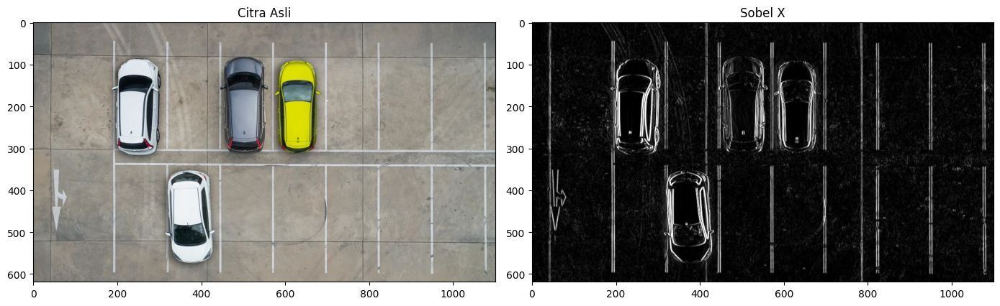

In [ ]:
folder = '/content/drive/MyDrive/PCVK/Images (2)/Images/Object Detection'
img_path = os.path.join(folder, 'car-park.jpg')

img = cv.imread(img_path)

if img is None:
  raise FileNotFoundError(
      "Gambar tidak ditemukan!"
  )

gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

blur = cv.GaussianBlur(gray, (3, 3), 0)

sobel_x = cv.Sobel(blur, cv.CV_64F, 1, 0, ksize=3)
sobel_y = cv.Sobel(blur, cv.CV_64F, 0, 1, ksize=3)

sobel_x = cv.convertScaleAbs(sobel_x)
sobel_y = cv.convertScaleAbs(sobel_y)

sobel_combined = cv.addWeighted(
    sobel_x, 0.5,
    sobel_y, 0.5,
    0
)

canny = cv.Canny(blur, 50, 150)
laplacian = cv.Laplacian(blur, cv.CV_64F, ksize=3)
laplacian = cv.convertScaleAbs(laplacian)

plt.figure(figsize=(14, 10))

plt.subplot(2, 2, 1)
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('Citra Asli')

plt.subplot(2, 2, 2)
plt.imshow(sobel_x, cmap='gray')
plt.title('Sobel X')

plt.tight_layout()
plt.show()

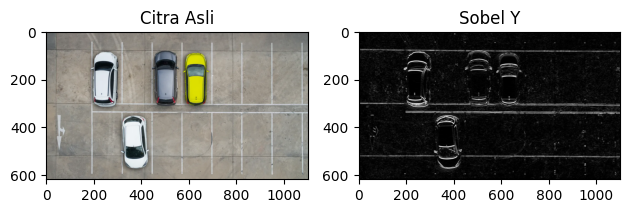

In [ ]:
plt.subplot(2, 2, 1)
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('Citra Asli')

plt.subplot(2, 2, 2)
plt.imshow(sobel_y, cmap='gray')
plt.title('Sobel Y')

plt.tight_layout()
plt.show()

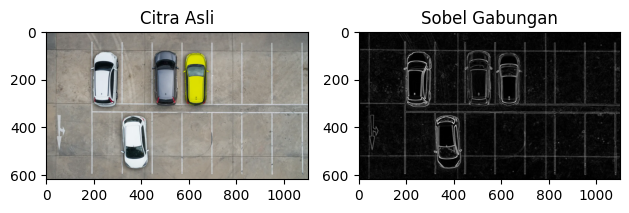

In [ ]:
plt.subplot(2, 2, 1)
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('Citra Asli')

plt.subplot(2, 2, 2)
plt.imshow(sobel_combined, cmap='gray')
plt.title('Sobel Gabungan')

plt.tight_layout()
plt.show()

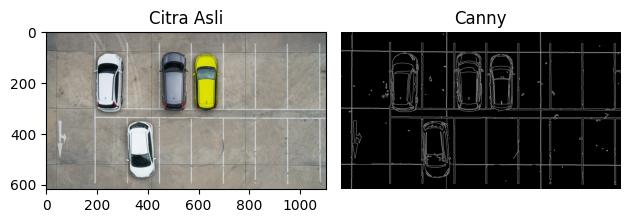

In [ ]:
plt.subplot(2, 2, 1)
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('Citra Asli')

plt.subplot(2, 2, 2)
plt.imshow(canny, cmap='gray')
plt.title('Canny')
plt.axis('off')

plt.tight_layout()
plt.show()

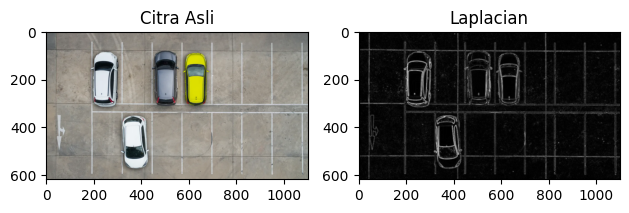

In [ ]:
plt.subplot(2, 2, 1)
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('Citra Asli')

plt.subplot(2, 2, 2)
plt.imshow(laplacian, cmap='gray')
plt.title('Laplacian')

plt.tight_layout()
plt.show()

###5. Implementasikan metode Harris Corner Detection dan Shi-Tomasi  Detection pada OpenCV dengan menggunakan gambar chess board.jpg

Jumlah sudut Shi-Tomasi: 100


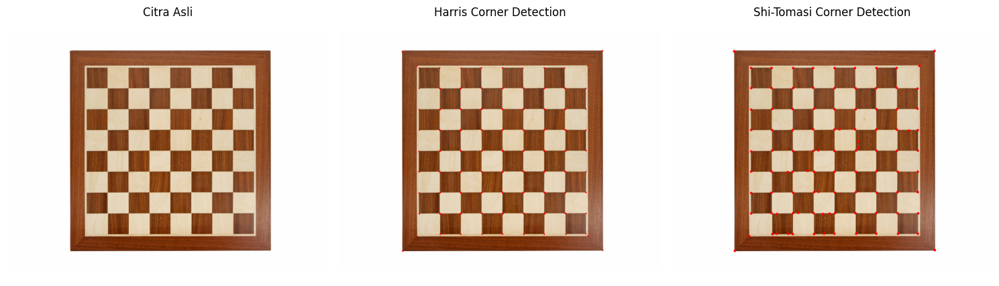

In [ ]:
folder = '/content/drive/MyDrive/PCVK/Images (2)/Images/Object Detection'
img_path = os.path.join(folder, 'chess-board.jpg')

img = cv.imread(img_path)

if img is None:
  raise FileNotFoundError(
      "Gambar tidak ditemukan!"
  )

gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
gray_float = np.float32(gray)

harris = cv.cornerHarris(
    gray_float,
    blockSize=2,
    ksize=3,
    k=0.04
)

harris = cv.dilate(harris, None)
harris_result = img.copy()
harris_result[harris > 0.01 * harris.max()] = [0, 0, 255]

shi_result = img.copy()
corners = cv.goodFeaturesToTrack(
    gray,
    maxCorners=100,
    qualityLevel=0.01,
    minDistance=10,
    blockSize=3,
    useHarrisDetector=False
)

if corners is not None:
  corners = np.int32(corners)
  for corner in corners:
    x, y = corner.ravel()
    cv.circle(shi_result, (x, y), 4, (0, 0, 255), -1)

  print("Jumlah sudut Shi-Tomasi:",len(corners))
else:
  print("Tidak ada sudut yang terdeteksi oleh Shi-Tomasi.")

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('Citra Asli')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(cv.cvtColor(harris_result, cv.COLOR_BGR2RGB))
plt.title('Harris Corner Detection')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(cv.cvtColor(shi_result, cv.COLOR_BGR2RGB))
plt.title('Shi-Tomasi Corner Detection')
plt.axis('off')

plt.tight_layout()
plt.show()


###6. Implementasikan metode Hough Transform pada OpenCV dengan menggunakan gambar sudoku.jpg.

Jumlah garis horizontal: 3
Jumlah garis vertikal: 0


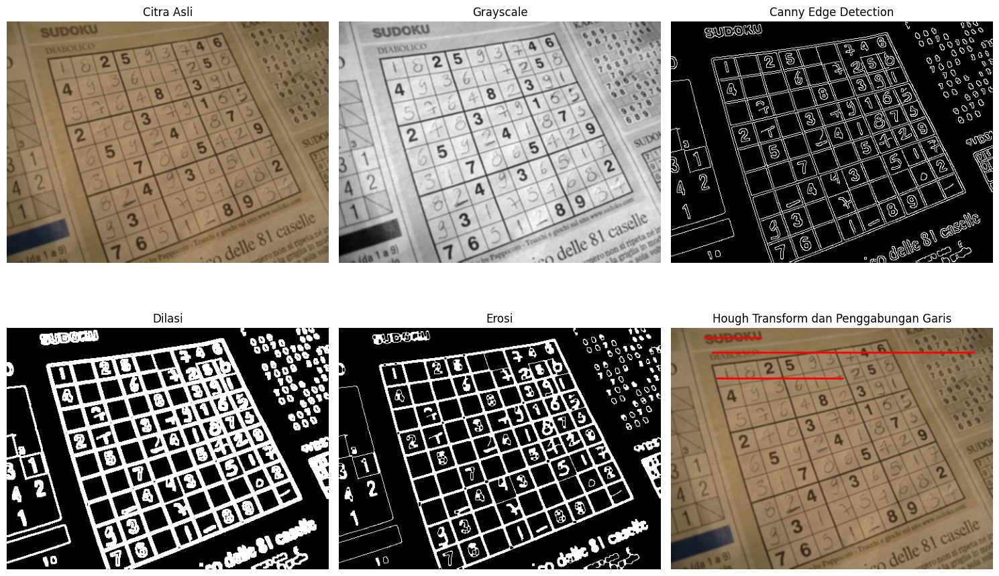

In [ ]:
folder = '/content/drive/MyDrive/PCVK/Images (2)/Images/Object Detection'
img_path = os.path.join(folder, 'sudoku.jpg')

img = cv.imread(img_path)

if img is None:
  raise FileNotFoundError(
      "Gambar tidak ditemukan!"
  )

gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
blur = cv.GaussianBlur(gray, (3, 3), 0)
edges = cv.Canny(blur, 50, 150)
kernel = np.ones((3, 3), np.uint8)
dilated = cv.dilate(edges, kernel, iterations=1)
eroded = cv.erode(dilated, kernel, iterations=1)

lines = cv.HoughLinesP(
    eroded,
    rho=1,
    theta=np.pi / 180,
    threshold=100,
    minLineLength=50,
    maxLineGap=10
)

horizontal_lines = []
vertical_lines = []

if lines is not None:
  for line in lines:
    x1, y1, x2, y2 = np.array(line).reshape(-1)[:4]

    dx = x2 - x1
    dy = y2 - y1
    angle = np.degrees(np.arctan2(dy, dx))

    if abs(angle) < 10 or abs(angle) > 170:
      y = (y1 + y2)// 2
      horizontal_lines.append((y, x1, x2))

    elif 80 < abs(angle) < 100:
      x = (x1 + x2) // 2
      vertical_lines.append((x, y1, y2))

def merge_horizontal(lines, distance=10):
  if not lines:
    return[]

  lines = sorted(lines, key=lambda item: item[0])
  merged = []
  group = [lines[0]]

  for line in lines[1:]:
    if line[0] - group[-1][0] <= distance:
      group.append(line)
    else:
      y = int(np.mean([item[0] for item in group]))
      x1 = min(item[1] for item in group)
      x2 = max(item[2] for item in group)
      merged.append((x1, y, x2, y))
      group = [line]

  y = int(np.mean([item[0] for item in group]))
  x1 = min(item[1] for item in group)
  x2 = max(item[2] for item in group)
  merged.append((x1, y, x2, y))

  return merged

def merge_vertical(lines, distance=10):
  if not lines:
    return[]

  lines = sorted(lines, key=lambda item: item[0])
  merged=[]
  group = [lines[0]]

  for line in lines[1:]:
    if line[0] - group[-1][0] <= distance:
      group.append(line)
    else:
      x = int(np.mean([item[0] for item in group]))
      y1 = min(item[1] for item in group)
      y2 = max(item[2] for item in group)
      merged.append((x, y1, x, y2))
      group = [line]

  x = int(np.mean([item[0] for item in group]))
  y1 = min(item[1] for item in group)
  y2 = max(item[2] for item in group)
  merged.append((x, y1, x, y2))

  return merged

merged_horizontal = merge_horizontal(horizontal_lines)
merged_vertical = merge_vertical(vertical_lines)

result = img.copy()

for x1, y1, x2, y2 in merged_horizontal:
  cv.line(result, (x1, y1), (x2, y2), (0, 0, 255), 2)

for x1, y1, x2, y2 in merged_vertical:
  cv.line(result, (x1, y1), (x2, y2), (0, 255, 0), 2)

print("Jumlah garis horizontal:", len(merged_horizontal))
print("Jumlah garis vertikal:", len(merged_vertical))

plt.figure(figsize=(15, 10))

plt.subplot(2, 3, 1)
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('Citra Asli')
plt.axis('off')

plt.subplot(2, 3, 2)
plt.imshow(gray, cmap='gray')
plt.title('Grayscale')
plt.axis('off')

plt.subplot(2, 3, 3)
plt.imshow(edges, cmap='gray')
plt.title('Canny Edge Detection')
plt.axis('off')

plt.subplot(2, 3, 4)
plt.imshow(dilated, cmap='gray')
plt.title('Dilasi')
plt.axis('off')

plt.subplot(2, 3, 5)
plt.imshow(eroded, cmap='gray')
plt.title('Erosi')
plt.axis('off')

plt.subplot(2, 3, 6)
plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
plt.title('Hough Transform dan Penggabungan Garis')
plt.axis('off')

plt.tight_layout()
plt.show()

###7. Implementasikan fungsi findContours() pada OpenCV untuk contour detection dengan menggunakan gambar laptop.jpg

Jumlah kontur yang terdeteksi: 554


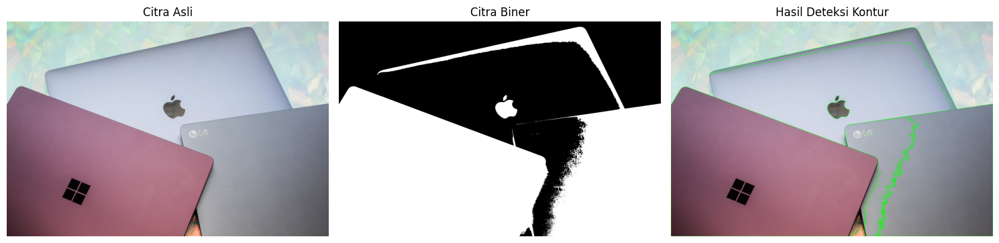

In [ ]:
folder = '/content/drive/MyDrive/PCVK/Images (2)/Images/Object Detection'
img_path = os.path.join(folder, 'laptop.jpg')

img = cv.imread(img_path)

if img is None:
  raise FileNotFoundError(
    "Gambar tidak ditemukan"
)

gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
blur = cv.GaussianBlur(gray, (5,5), 0)

_, thresh = cv.threshold(
    blur, 0, 255, cv.THRESH_BINARY_INV + cv.THRESH_OTSU
)

contours, hierarchy = cv.findContours(
    thresh,
    cv.RETR_EXTERNAL,
    cv.CHAIN_APPROX_SIMPLE
)

print("Jumlah kontur yang terdeteksi:", len(contours))

result = img.copy()

cv.drawContours(
    result,
    contours,
    -1,
    (0, 255, 0),
    2
)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('Citra Asli')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(thresh, cmap='gray')
plt.title('Citra Biner')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
plt.title('Hasil Deteksi Kontur')
plt.axis('off')

plt.tight_layout()
plt.show()


##D2. Praktikum Feature Matching dan Face Detection

###8. Face Detection untuk image object lain yang tersedia pada (/images/facedet).

In [ ]:
!pip uninstall -y opencv-python opencv-contrib-python opencv-python-headless opencv-contrib-python-headless
!pip install opencv-contrib-python

Found existing installation: opencv-contrib-python 5.0.0.93
Uninstalling opencv-contrib-python-5.0.0.93:
  Successfully uninstalled opencv-contrib-python-5.0.0.93
  Using cached opencv_contrib_python-5.0.0.93-cp37-abi3-manylinux_2_28_x86_64.whl.metadata (19 kB)
Using cached opencv_contrib_python-5.0.0.93-cp37-abi3-manylinux_2_28_x86_64.whl (82.1 MB)


dog.jpg: 3 wajah terdeteksi
jokowi.jpg: 2 wajah terdeteksi
kartini.jpg: 1 wajah terdeteksi
kucing.jpg: 0 wajah terdeteksi
many_cereals.jpg: 0 wajah terdeteksi
mask.png: 5 wajah terdeteksi
mjordan.jpg: 2 wajah terdeteksi
mycat.jpg: 1 wajah terdeteksi
people.jpg: 9 wajah terdeteksi
prabowo.jpg: 1 wajah terdeteksi
reeses_puffs.png: 0 wajah terdeteksi
smile.png: 0 wajah terdeteksi
solvayconf.jpg: 23 wajah terdeteksi


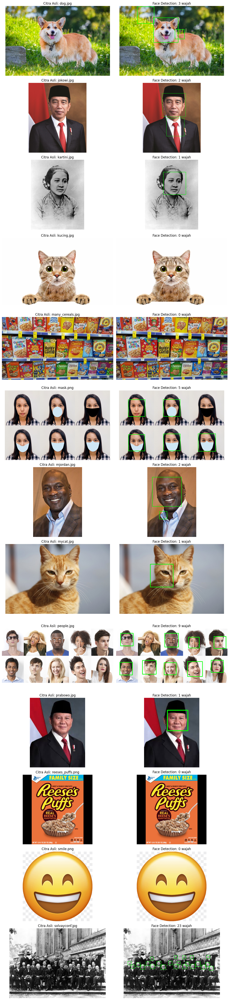

In [ ]:
import math

base_folder = '/content/drive/MyDrive/PCVK/Images (2)/Images'

image_folder = os.path.join(base_folder, 'facedet')
cascade_folder = os.path.join(base_folder, 'haarcascades')

cascade_path = os.path.join(
    cascade_folder,
    'haarcascade_frontalface_default.xml'
)

face_cascade = cv.CascadeClassifier(cascade_path)

if face_cascade.empty():
    raise RuntimeError("Haar Cascade gagal dimuat!")

image_files = [
    f for f in sorted(os.listdir(image_folder))
    if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))
]

if not image_files:
    raise FileNotFoundError("Tidak ada gambar di folder facedet!")

total_images = len(image_files)
cols = 2
rows = total_images

plt.figure(figsize=(12, rows * 4))

for i, filename in enumerate(image_files):
    img_path = os.path.join(image_folder, filename)
    img = cv.imread(img_path)

    if img is None:
        print("Gambar gagal dibaca:", filename)
        continue

    gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

    faces = face_cascade.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(30, 30)
    )

    print(f"{filename}: {len(faces)} wajah terdeteksi")

    result = img.copy()

    for (x, y, w, h) in faces:
        cv.rectangle(
            result,
            (x, y),
            (x + w, y + h),
            (0, 255, 0),
            2
        )

    plt.subplot(rows, cols, 2 * i + 1)
    plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    plt.title(f'Citra Asli: {filename}')
    plt.axis('off')

    plt.subplot(rows, cols, 2 * i + 2)
    plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
    plt.title(f'Face Detection: {len(faces)} wajah')
    plt.axis('off')

plt.tight_layout()
plt.show()

###9. deteksi wajah kucing hingga muncul rectangle pada bagian wajah kucing

Gambar yang digunakan: kucing.jpg
Jumlah wajah kucing terdeteksi: 2


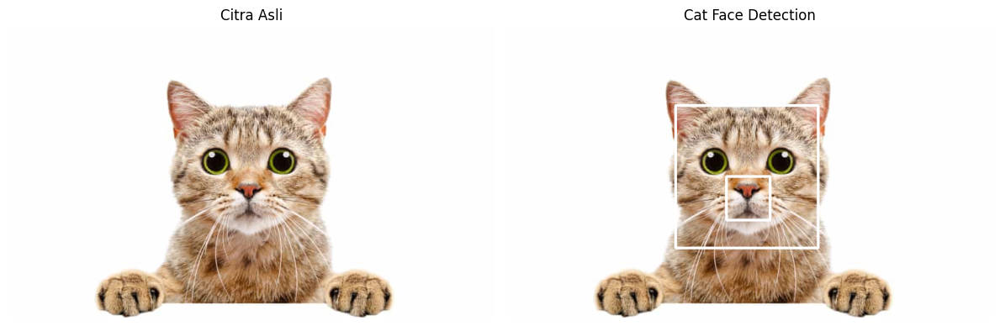

In [ ]:
import urllib.request

base_folder = '/content/drive/MyDrive/PCVK/Images (2)/Images'
image_folder = os.path.join(base_folder, 'facedet')
cascade_folder = os.path.join(base_folder, 'haarcascades')

os.makedirs(cascade_folder, exist_ok=True)

image_files = [
    f for f in os.listdir(image_folder)
    if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))
]

cat_files = [
    f for f in image_files
    if 'cat' in f.lower() or 'kucing' in f.lower()
]

if not cat_files:
    print("Gambar yang tersedia:", image_files)
    raise FileNotFoundError(
        "Gambar kucing tidak ditemukan. Periksa folder facedet."
    )

img_path = os.path.join(image_folder, sorted(cat_files)[0])
img = cv.imread(img_path)

if img is None:
    raise FileNotFoundError("Gambar kucing gagal dibaca!")

print("Gambar yang digunakan:", os.path.basename(img_path))

cascade_path = os.path.join(
    cascade_folder,
    'haarcascade_frontalcatface.xml'
)

if not os.path.isfile(cascade_path):
    url = (
        'https://raw.githubusercontent.com/opencv/opencv/'
        '4.x/data/haarcascades/haarcascade_frontalcatface.xml'
    )

    print("Mengunduh Haar Cascade khusus kucing...")

    urllib.request.urlretrieve(url, cascade_path)

    print("Download berhasil!")

cat_cascade = cv.CascadeClassifier(cascade_path)

if cat_cascade.empty():
    raise RuntimeError("Haar Cascade kucing gagal dimuat!")

gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
cats = cat_cascade.detectMultiScale(
    gray,
    scaleFactor=1.1,
    minNeighbors=3,
    minSize=(30, 30)
)

print("Jumlah wajah kucing terdeteksi:", len(cats))

result = img.copy()
for (x, y, w, h) in cats:
    cv.rectangle(
        result,
        (x, y),
        (x + w, y + h),
        (255, 255, 255),
        3
    )

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('Citra Asli')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
plt.title('Cat Face Detection')
plt.axis('off')

plt.tight_layout()
plt.show()

###10. Cobakan juga untuk eyes detection pada wajah Pak Prabowo

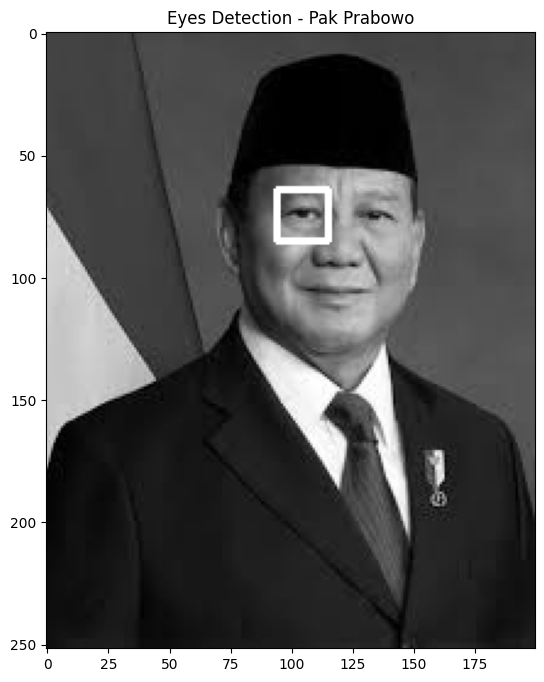

Jumlah wajah terdeteksi: 1


In [ ]:
base_folder = '/content/drive/MyDrive/PCVK/Images (2)/Images'
image_folder = os.path.join(base_folder, 'facedet')
cascade_folder = os.path.join(base_folder, 'haarcascades')

image_files = [
    f for f in os.listdir(image_folder)
    if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))
]

prabowo_files = [
    f for f in image_files
    if 'prabowo' in f.lower()
]

if not prabowo_files:
    print("Gambar Pak Prabowo tidak ditemukan.")
    print("Daftar gambar yang tersedia:", image_files)
    raise FileNotFoundError("Silakan periksa nama file gambar Pak Prabowo.")

img_path = os.path.join(image_folder, prabowo_files[0])
img = cv.imread(img_path)

if img is None:
    raise ValueError("Gambar gagal dibaca.")

os.makedirs(cascade_folder, exist_ok=True)

face_path = os.path.join(
    cascade_folder, 'haarcascade_frontalface_default.xml'
)
eye_path = os.path.join(
    cascade_folder, 'haarcascade_eye.xml'
)

if not os.path.exists(face_path):
    urllib.request.urlretrieve(
        'https://raw.githubusercontent.com/opencv/opencv/4.x/data/haarcascades/haarcascade_frontalface_default.xml',
        face_path
    )

if not os.path.exists(eye_path):
    urllib.request.urlretrieve(
        'https://raw.githubusercontent.com/opencv/opencv/4.x/data/haarcascades/haarcascade_eye.xml',
        eye_path
    )

face_cascade = cv.CascadeClassifier(face_path)
eye_cascade = cv.CascadeClassifier(eye_path)

if face_cascade.empty() or eye_cascade.empty():
    raise ValueError("File Haar Cascade gagal dimuat.")

gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
faces = face_cascade.detectMultiScale(
    gray,
    scaleFactor=1.1,
    minNeighbors=5,
    minSize=(30, 30)
)

result = cv.cvtColor(gray, cv.COLOR_GRAY2BGR)
for (x, y, w, h) in faces:

    roi_gray = gray[y:y+h, x:x+w]

    eyes = eye_cascade.detectMultiScale(
        roi_gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(10, 10)
    )

    for (ex, ey, ew, eh) in eyes:
        cv.rectangle(
            result,
            (x + ex, y + ey),
            (x + ex + ew, y + ey + eh),
            (255, 255, 255),
            2
        )

plt.figure(figsize=(8, 8))
plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
plt.title('Eyes Detection - Pak Prabowo')
plt.axis('on')
plt.show()

print("Jumlah wajah terdeteksi:", len(faces))

###11. Lakukan deteksi senyuman pada gambar people

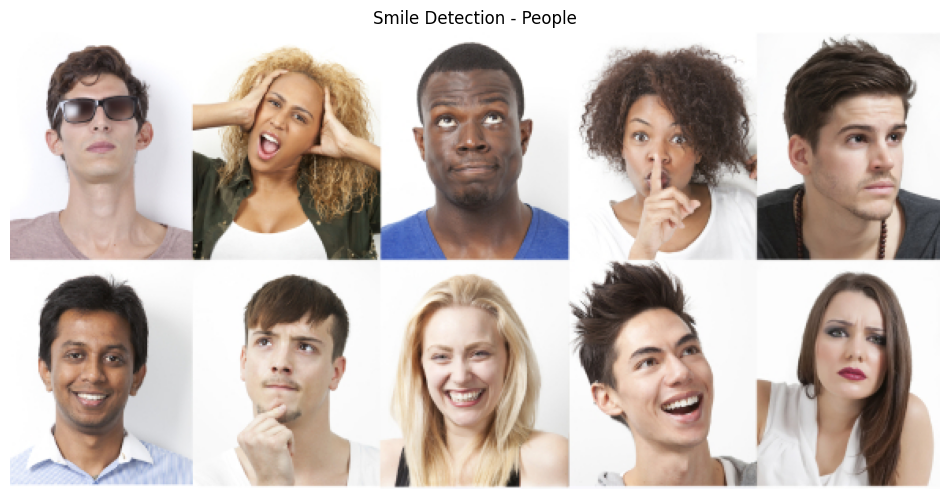

Jumlah wajah terdeteksi: 9
Jumlah senyuman terdeteksi: 0


In [ ]:
base_folder = '/content/drive/MyDrive/PCVK/Images (2)/Images'
image_folder = os.path.join(base_folder, 'facedet')
cascade_folder = os.path.join(base_folder, 'haarcascades')

os.makedirs(cascade_folder, exist_ok=True)

image_files = [
    f for f in os.listdir(image_folder)
    if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))
]

people_files = [
    f for f in image_files
    if 'people' in f.lower()
]

if not people_files:
    print("Gambar people tidak ditemukan.")
    print("Daftar gambar tersedia:", image_files)
    raise FileNotFoundError("Periksa nama file gambar people.")

img_path = os.path.join(image_folder, people_files[0])
img = cv.imread(img_path)

if img is None:
    raise ValueError("Gambar gagal dibaca.")

face_path = os.path.join(
    cascade_folder, 'haarcascade_frontalface_default.xml'
)

smile_path = os.path.join(
    cascade_folder, 'haarcascade_smile.xml'
)

if not os.path.exists(face_path):
    urllib.request.urlretrieve(
        'https://raw.githubusercontent.com/opencv/opencv/4.x/data/haarcascades/haarcascade_frontalface_default.xml',
        face_path
    )

if not os.path.exists(smile_path):
    urllib.request.urlretrieve(
        'https://raw.githubusercontent.com/opencv/opencv/4.x/data/haarcascades/haarcascade_smile.xml',
        smile_path
    )

face_cascade = cv.CascadeClassifier(face_path)
smile_cascade = cv.CascadeClassifier(smile_path)

if face_cascade.empty() or smile_cascade.empty():
    raise ValueError("File Haar Cascade gagal dimuat.")

gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
faces = face_cascade.detectMultiScale(
    gray,
    scaleFactor=1.1,
    minNeighbors=5,
    minSize=(30, 30)
)

result = img.copy()
total_smiles = 0

for (x, y, w, h) in faces:

    roi_gray = gray[y:y+h, x:x+w]
    lower_face = roi_gray[h//2:h, :]
    smiles = smile_cascade.detectMultiScale(
        lower_face,
        scaleFactor=1.7,
        minNeighbors=20,
        minSize=(15, 10)
    )

    for (sx, sy, sw, sh) in smiles:
        cv.rectangle(
            result,
            (x + sx, y + h//2 + sy),
            (x + sx + sw, y + h//2 + sy + sh),
            (0, 255, 0),
            2
        )
        total_smiles += 1

plt.figure(figsize=(12, 8))
plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
plt.title('Smile Detection - People')
plt.axis('off')
plt.show()

print("Jumlah wajah terdeteksi:", len(faces))
print("Jumlah senyuman terdeteksi:", total_smiles)

###12. Lakukan Face Tracking menggunakan Google Colab.

In [ ]:
import base64
import urllib.request
from IPython.display import display, HTML
from google.colab.output import register_callback

cascade_path = '/content/haarcascade_frontalface_default.xml'

url = 'https://raw.githubusercontent.com/opencv/opencv/4.x/data/haarcascades/haarcascade_frontalface_default.xml'

if not os.path.exists(cascade_path) or os.path.getsize(cascade_path) == 0:
    urllib.request.urlretrieve(url, cascade_path)

face_cascade = cv.CascadeClassifier(cascade_path)

if face_cascade.empty():
    raise ValueError("Haar Cascade gagal dimuat. Periksa file XML.")

def process_frame(data):
    image_data = data.split(',')[1]
    image_bytes = base64.b64decode(image_data)

    np_arr = np.frombuffer(image_bytes, np.uint8)
    frame = cv.imdecode(np_arr, cv.IMREAD_COLOR)

    if frame is None:
        raise ValueError("Frame kamera gagal dibaca.")

    gray = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)

    faces = face_cascade.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(30, 30)
    )

    for (x, y, w, h) in faces:
        cv.rectangle(
            frame,
            (x, y),
            (x + w, y + h),
            (0, 255, 0),
            2
        )

        cv.putText(
            frame,
            'Face Detected',
            (x, y - 10),
            cv.FONT_HERSHEY_SIMPLEX,
            0.6,
            (0, 255, 0),
            2
        )

    _, buffer = cv.imencode('.jpg', frame)
    result = base64.b64encode(buffer).decode('utf-8')

    return {
        'image': result,
        'faces': len(faces)
    }

register_callback('notebook.process_frame', process_frame)

display(HTML("""
<div style="text-align:center">
    <h3>Face Tracking - OpenCV</h3>

    <video id="webcam" autoplay playsinline
        style="width:100%;max-width:500px;display:none">
    </video>

    <canvas id="canvas" style="display:none"></canvas>

    <img id="output"
        style="width:100%;max-width:500px;border:2px solid green">

    <p id="status">Kamera belum dijalankan.</p>

    <button id="start"
        style="padding:10px 20px;background:green;color:white;border:0">
        Start Camera
    </button>

    <button id="stop"
        style="padding:10px 20px;background:red;color:white;border:0">
        Stop Camera
    </button>
</div>

<script>
(async function() {
    const video = document.getElementById('webcam');
    const canvas = document.getElementById('canvas');
    const output = document.getElementById('output');
    const status = document.getElementById('status');
    const start = document.getElementById('start');
    const stop = document.getElementById('stop');
    const context = canvas.getContext('2d');

    let stream = null;
    let running = false;
    let busy = false;

    start.onclick = async function() {
        try {
            stream = await navigator.mediaDevices.getUserMedia({
                video: true
            });

            video.srcObject = stream;
            await video.play();

            canvas.width = video.videoWidth;
            canvas.height = video.videoHeight;

            running = true;
            status.innerText = 'Face Tracking sedang berjalan...';

            trackFace();

        } catch (error) {
            status.innerText = 'Tidak dapat mengakses kamera: ' + error;
        }
    };

    async function trackFace() {
        if (!running) return;

        if (!busy && video.readyState >= 2) {
            busy = true;

            context.drawImage(
                video, 0, 0, canvas.width, canvas.height
            );

            const frame = canvas.toDataURL('image/jpeg', 0.7);

            try {
                const response = await google.colab.kernel.invokeFunction(
                    'notebook.process_frame',
                    [frame],
                    {}
                );

                const result = response.data;

                output.src = 'data:image/jpeg;base64,' + result.image;

                status.innerText =
                    'Jumlah wajah terdeteksi: ' + result.faces;

            } catch (error) {
                status.innerText = 'Terjadi kesalahan: ' + error;
            }

            busy = false;
        }

        if (running) {
            setTimeout(trackFace, 200);
        }
    }

    stop.onclick = function() {
        running = false;

        if (stream) {
            stream.getTracks().forEach(track => track.stop());
            stream = null;
        }

        video.srcObject = null;
        status.innerText = 'Face Tracking dihentikan.';
        output.src = '';
    };
})();
</script>
"""))

###13. Lakukan Blurring pada bagian wajah yang terdeteksi.

Gambar yang digunakan: prabowo.jpg


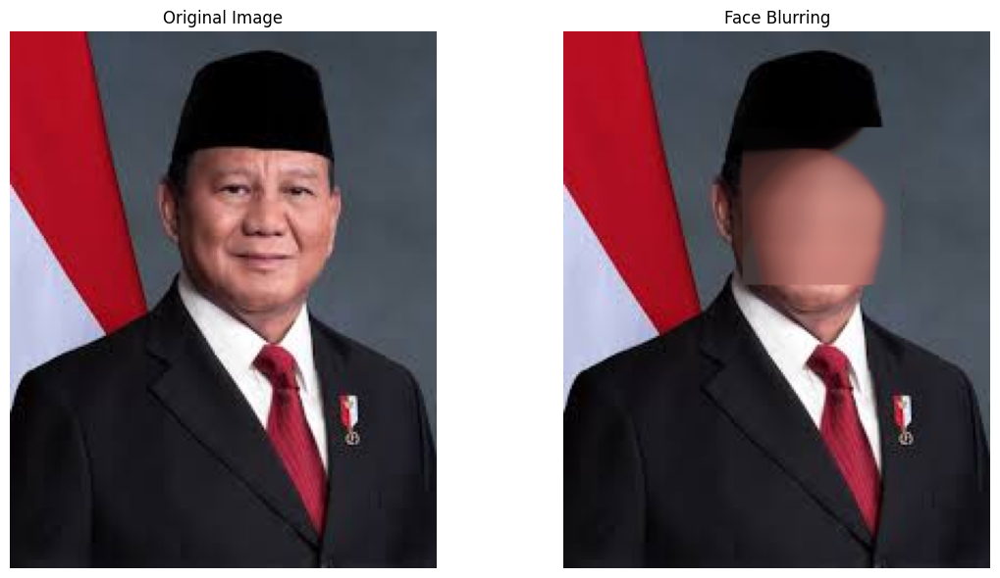

Jumlah wajah yang terdeteksi: 1


In [ ]:
base_folder = '/content/drive/MyDrive/PCVK/Images (2)/Images'
image_folder = os.path.join(base_folder, 'facedet')

cascade_path = '/content/haarcascade_frontalface_default.xml'

if not os.path.exists(cascade_path):
    url = 'https://raw.githubusercontent.com/opencv/opencv/4.x/data/haarcascades/haarcascade_frontalface_default.xml'
    urllib.request.urlretrieve(url, cascade_path)

face_cascade = cv.CascadeClassifier(cascade_path)

if face_cascade.empty():
    raise ValueError("Haar Cascade gagal dimuat.")

image_files = [
    f for f in os.listdir(image_folder)
    if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))
]

selected_img = None
selected_name = None
faces = None

for filename in image_files:
    img_path = os.path.join(image_folder, filename)
    img = cv.imread(img_path)

    if img is None:
        continue

    gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

    detected_faces = face_cascade.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(30, 30)
    )

    if len(detected_faces) > 0:
        selected_img = img
        selected_name = filename
        faces = detected_faces
        break

if selected_img is None:
    raise FileNotFoundError("Tidak ditemukan gambar dengan wajah.")

print("Gambar yang digunakan:", selected_name)

result = selected_img.copy()
for (x, y, w, h) in faces:

    face_roi = result[y:y+h, x:x+w]
    blurred_face = cv.medianBlur(face_roi, 51)
    result[y:y+h, x:x+w] = blurred_face

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv.cvtColor(selected_img, cv.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
plt.title('Face Blurring')
plt.axis('off')

plt.tight_layout()
plt.show()

print("Jumlah wajah yang terdeteksi:", len(faces))

###14. Mengolah gambar KTM masing-masing

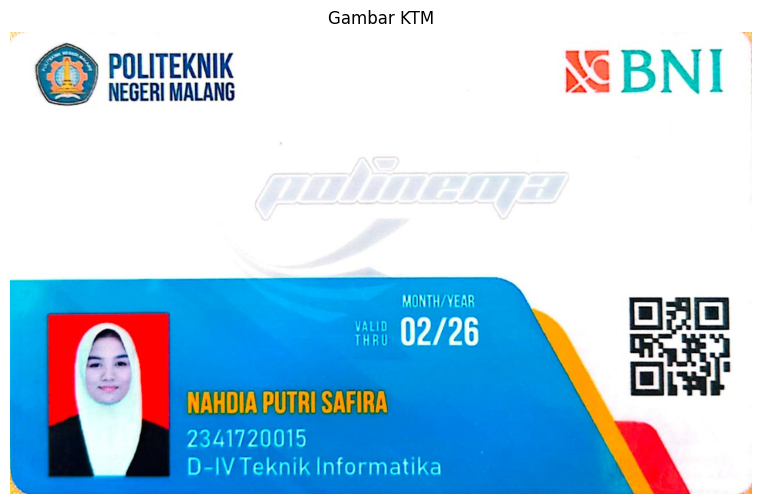

In [ ]:
ktm_path = '/content/drive/MyDrive/PCVK/Images (2)/Images/KTM Baru.jpg'
ktm = cv.imread(ktm_path)

if ktm is None:
    raise FileNotFoundError("Gambar KTM tidak ditemukan. Periksa lokasi file.")

plt.figure(figsize=(10, 6))
plt.imshow(cv.cvtColor(ktm, cv.COLOR_BGR2RGB))
plt.title('Gambar KTM')
plt.axis('off')
plt.show()

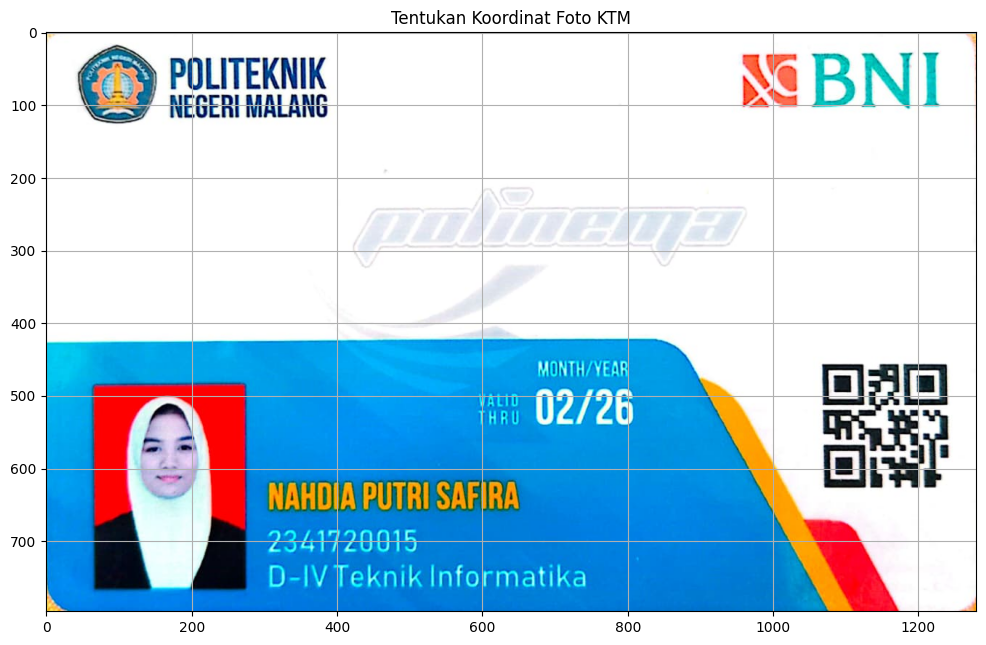

Ukuran gambar (tinggi, lebar): (797, 1280)


In [ ]:
plt.figure(figsize=(12, 8))
plt.imshow(cv.cvtColor(ktm, cv.COLOR_BGR2RGB))
plt.title('Tentukan Koordinat Foto KTM')
plt.grid()
plt.show()

print("Ukuran gambar (tinggi, lebar):", ktm.shape[:2])

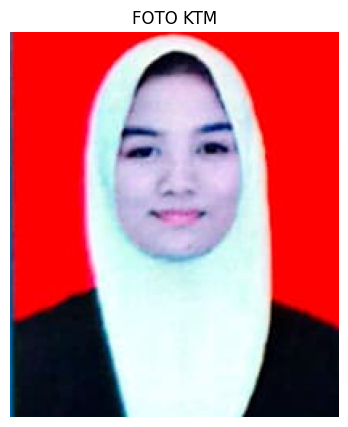

Ukuran foto profil: (240, 205, 3)


In [ ]:
x1, y1 = 65, 500
x2, y2 = 270, 740

foto_ktm = ktm[y1:y2, x1:x2]

plt.figure(figsize=(5, 5))
plt.imshow(cv.cvtColor(foto_ktm, cv.COLOR_BGR2RGB))
plt.title('FOTO KTM')
plt.axis('off')
plt.show()

print("Ukuran foto profil:", foto_ktm.shape)

In [ ]:
import os
import cv2
import random
import numpy as np
import pickle
from tqdm import tqdm

DATADIR = "dataset/training"      # satu subfolder per karakter: 0..9, A..Z
width, height = 100, 100

dirs = sorted(os.listdir(DATADIR))        # daftar nama kelas
training_data = []

for char_name in dirs:
    path = os.path.join(DATADIR, char_name)
    class_number = dirs.index(char_name)
    for img in tqdm(os.listdir(path), desc=char_name):
        try:
            img_array = cv2.imread(os.path.join(path, img),
                                   cv2.IMREAD_GRAYSCALE)
            new_array = cv2.resize(img_array, (width, height))
            training_data.append([new_array, class_number])
        except Exception:
            pass

random.shuffle(training_data)

X, Y = [], []
for feature, label in training_data:
    X.append(feature)
    Y.append(label)

X = np.array(X).reshape(-1, width, height, 1)
Y = np.array(Y)

pickle.dump(X,    open("X.pickle", "wb"))
pickle.dump(Y,    open("Y.pickle", "wb"))
pickle.dump(dirs, open("kelas.pickle", "wb"))

print("jumlah data :", len(training_data))
print("jumlah kelas:", len(dirs), dirs)

FileNotFoundError: [Errno 2] No such file or directory: 'dataset/training'